[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JPEDROPS092/machine-learning-algorithms/blob/main/notebooks/08-churn-regressao-logistica.ipynb)

# Cancelamento de telefonia com regressao logistica

O conjunto e o Telco Customer Churn, amostra publica da IBM para o problema de cancelamento de clientes de telefonia. O arquivo usado e `Telco-Customer-Churn.csv` do repositorio `IBM/telco-customer-churn-on-icp4d`. Sao 7.043 linhas, uma por cliente, com a coluna `Churn` (`Yes` ou `No`). Nao ha login.

Ficam de fora `customerID` e os atributos de genero, parceiro e dependentes. O caderno modela a relacao de servico (tempo de casa, conta, contrato, internet, suporte), nao o perfil demografico. `TotalCharges` vem como texto quando a conta ainda nao fechou; essas linhas viram ausente e sao removidas, e a quantidade removida e impressa.


In [1]:
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip install -q numpy pandas scikit-learn matplotlib seaborn requests
    import os
    if not os.path.isdir("/content/ml-algoritmos/src/mlalgos"):
        !git clone --depth 1 https://github.com/JPEDROPS092/machine-learning-algorithms.git /content/ml-algoritmos
    if "/content/ml-algoritmos/src" not in sys.path:
        sys.path.insert(0, "/content/ml-algoritmos/src")
    PASTA_DADOS = Path("/content/data")
else:
    aqui = Path.cwd().resolve()
    raiz = aqui if (aqui / "src" / "mlalgos").exists() else aqui.parent
    if not (raiz / "src" / "mlalgos").exists():
        raise RuntimeError(
            "Nao encontrei src/mlalgos. Abra o notebook na pasta notebooks ou na raiz do repositorio."
        )
    if str(raiz / "src") not in sys.path:
        sys.path.insert(0, str(raiz / "src"))
    PASTA_DADOS = raiz / "data"

PASTA_DADOS.mkdir(parents=True, exist_ok=True)

%matplotlib inline
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110


def baixar(url, destino):
    """Baixa um arquivo so se ele ainda nao estiver na pasta data, que nao entra no git."""
    destino = Path(destino)
    if destino.exists() and destino.stat().st_size > 0:
        return destino
    import requests

    resposta = requests.get(url, timeout=180, headers={"User-Agent": "ml-algoritmos-aula/1.0"})
    resposta.raise_for_status()
    destino.write_bytes(resposta.content)
    return destino


def padronizar(treino, teste):
    """Z-score com media e desvio do treino. O teste usa os mesmos numeros, sem vazar."""
    treino = np.asarray(treino, dtype=float)
    teste = np.asarray(teste, dtype=float)
    media = treino.mean(axis=0)
    desvio = treino.std(axis=0)
    desvio = np.where(desvio == 0, 1.0, desvio)
    return (treino - media) / desvio, (teste - media) / desvio, media, desvio


## 1) Intuição

Uma operadora olha dois sinais simples: ha quanto tempo a pessoa e cliente e quanto paga por mes. Contrato mensal, sem suporte tecnico, conta subindo: o cancelamento fica mais plausivel. Contrato longo e conta estavel puxam para o outro lado. A regressao logistica junta esses sinais numa probabilidade de `Churn = Yes`. O limiar e uma decisao de negocio: ligar para muita gente, ou so para quem esta no topo da lista.


## 2) Fundamentação matemática

A regressao logistica desenha um escore linear e o espreme numa probabilidade. O escore e

$$
z = w^{\top} x + b
$$

- $x$ e o vetor de atributos da amostra.
- $w$ e o vetor de pesos, um por atributo.
- $b$ e o vies, o escore quando todos os atributos valem zero.
- $z$ e o logaritmo da chance, o log-odds: $\log \frac{p}{1-p} = z$.

A sigmoide converte $z$ na probabilidade da classe positiva:

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

- Se $z = 0$, $\sigma(z) = 0{,}5$.
- Se $z$ cresce, $\sigma(z)$ sobe em direcao a 1, sem nunca passar de 1.
- Se $z$ cai, $\sigma(z)$ desce em direcao a 0.
- A derivada $\sigma(z)\,(1-\sigma(z))$ e a que aparece no gradiente.

Com mais de duas classes, cada classe tem seu escore $z_k$ e a softmax divide as exponenciais:

$$
P(y = k \mid x) = \frac{e^{z_k}}{\sum_{c=1}^{K} e^{z_c}}
$$

- $z_k = w_k^{\top} x + b_k$ e o escore da classe $k$.
- $K$ e o numero de classes.
- O denominador faz as $K$ probabilidades somarem 1.
- Subtrair $\max_c z_c$ antes da exponencial nao muda o resultado e evita estouro numerico.

O treino minimiza a entropia cruzada, a surpresa media de ter previsto pouco a classe verdadeira, mais uma penalidade L2 so nos pesos:

$$
J(w, b) = -\frac{1}{n}\sum_{i=1}^{n}\Big[y_i \log \hat{p}_i + (1-y_i)\log(1-\hat{p}_i)\Big] + \frac{\lambda}{2}\|w\|^2
$$

- $n$ e o numero de amostras de treino.
- $y_i$ vale 1 na classe positiva e 0 na negativa.
- $\hat{p}_i = \sigma(w^{\top} x_i + b)$.
- $\lambda$ e o argumento `l2` do codigo. O vies $b$ nao entra em $\|w\|^2$: deslocar a fronteira nao deve ser punido do mesmo jeito que um peso enorme.
- No caso multiclasse, $y_i \log \hat{p}_i$ vira o log da probabilidade da classe correta.

A descida de gradiente anda no sentido em que $J$ diminui. Para a perda media acima, com a classe positiva codificada como 1:

$$
\frac{\partial J}{\partial w} = \frac{1}{n} X^{\top}(\hat{p} - y) + \lambda w, \qquad \frac{\partial J}{\partial b} = \frac{1}{n}\sum_{i=1}^{n}(\hat{p}_i - y_i)
$$

- $\hat{p} - y$ e o erro de cada amostra. Positivo quando o modelo exagerou a classe 1.
- $X^{\top}(\hat{p}-y)/n$ aponta quais atributos empurraram esse erro.
- $\lambda w$ encolhe os pesos em direcao a zero.
- O passo e $w \leftarrow w - \eta \, \partial J/\partial w$, e $\eta$ e o `learning_rate`.

O `C` do scikit-learn penaliza a soma dos erros, nao a media. Com $C = 1$, o $\lambda$ equivalente nesta media e $1/n$. E o valor usado nos cadernos para a comparacao ser justa. O otimizador deles (lbfgs) nao e o nosso passo fixo, entao os pesos nao precisam coincidir casa decimal; a qualidade no teste e que precisa ficar perto.


## 3) Visualização


linhas no arquivo 7043 fonte: IBM Telco Customer Churn
linhas removidas por TotalCharges vazio 11 restantes 7032
Churn
No     5163
Yes    1869
Name: count, dtype: int64


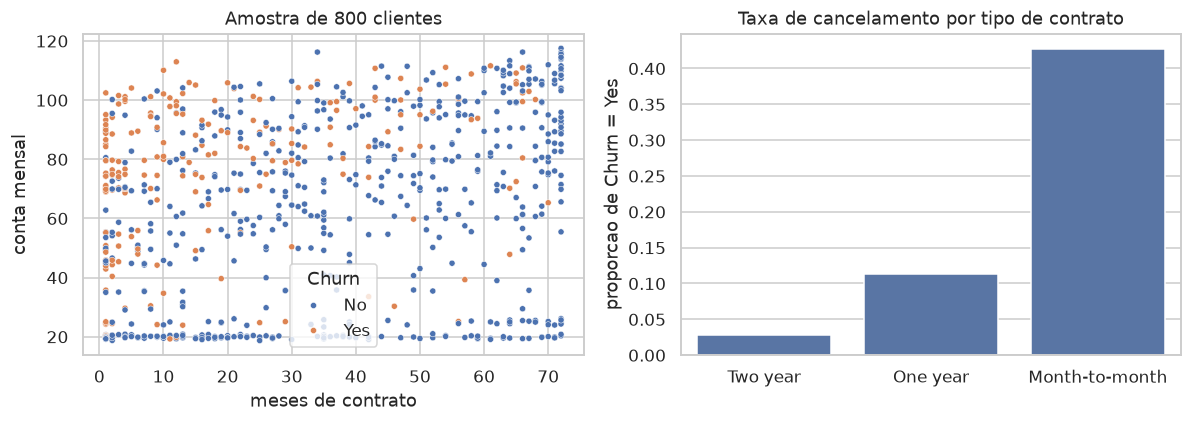

colunas 16 positivos no teste 467


In [2]:
arquivo = baixar(
    "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv",
    PASTA_DADOS / "telco-customer-churn.csv",
)
df = pd.read_csv(arquivo)
print("linhas no arquivo", len(df), "fonte: IBM Telco Customer Churn")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
faltando = int(df["TotalCharges"].isna().sum())
df = df.dropna(subset=["TotalCharges"]).copy()
print("linhas removidas por TotalCharges vazio", faltando, "restantes", len(df))
df["y"] = (df["Churn"] == "Yes").astype(int)
print(df["Churn"].value_counts())

fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
sns.scatterplot(data=df.sample(800, random_state=0), x="tenure", y="MonthlyCharges", hue="Churn", s=16, ax=eixos[0])
eixos[0].set_title("Amostra de 800 clientes")
eixos[0].set_xlabel("meses de contrato")
eixos[0].set_ylabel("conta mensal")
taxas = df.groupby("Contract")["y"].mean().sort_values()
sns.barplot(x=taxas.index, y=taxas.values, ax=eixos[1], color="#4c72b0")
eixos[1].set_title("Taxa de cancelamento por tipo de contrato")
eixos[1].set_ylabel("proporcao de Churn = Yes")
eixos[1].set_xlabel("")
plt.tight_layout()
plt.show()

from sklearn.model_selection import train_test_split

numericas = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]
categoricas = ["Contract", "InternetService", "PaymentMethod", "PaperlessBilling", "OnlineSecurity", "TechSupport"]
treino, teste = train_test_split(df, test_size=0.25, random_state=0, stratify=df["y"])
treino, teste = treino.copy(), teste.copy()
cat_tr = pd.get_dummies(treino[categoricas], drop_first=True)
cat_te = pd.get_dummies(teste[categoricas], drop_first=True).reindex(columns=cat_tr.columns, fill_value=0)
X_tr = np.column_stack([treino[numericas].to_numpy(float), cat_tr.to_numpy(float)])
X_te = np.column_stack([teste[numericas].to_numpy(float), cat_te.to_numpy(float)])
y_treino = treino["y"].to_numpy()
y_teste = teste["y"].to_numpy()
nomes = numericas + list(cat_tr.columns)
X_treino_p, X_teste_p, _, _ = padronizar(X_tr, X_te)
print("colunas", len(nomes), "positivos no teste", int(y_teste.sum()))


## 4) Implementação do zero


perda 0.6931 -> 0.4193


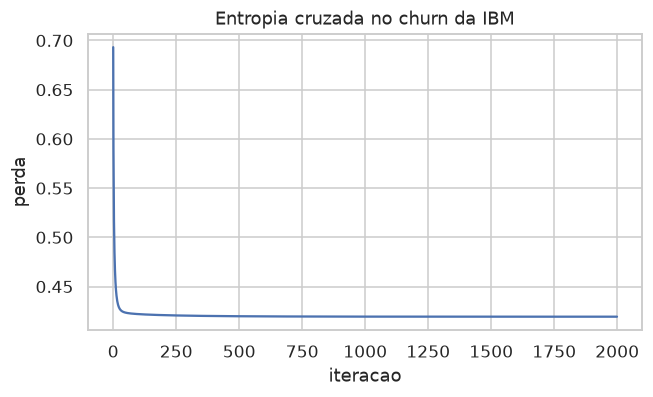

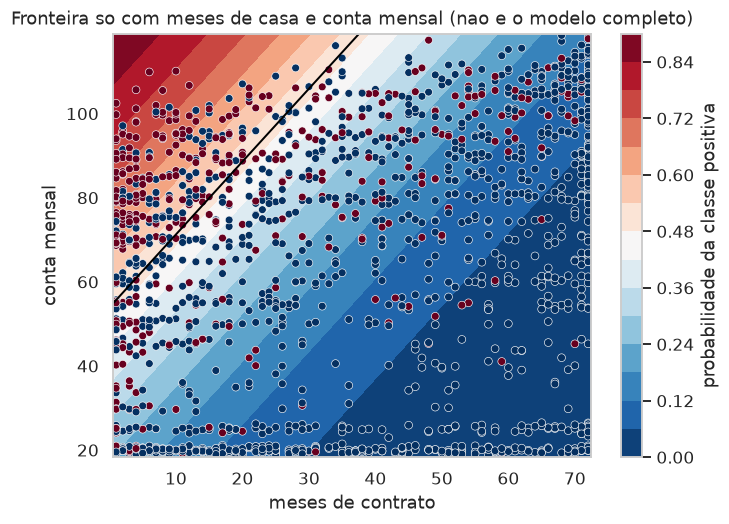

In [3]:
from mlalgos import LogisticRegression

l2 = 1.0 / len(X_treino_p)
modelo = LogisticRegression(learning_rate=0.6, n_iterations=2000, l2=l2).fit(X_treino_p, y_treino)
print("perda", round(modelo.loss_history_[0], 4), "->", round(modelo.loss_history_[-1], 4))
fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.plot(modelo.loss_history_)
ax.set_xlabel("iteracao")
ax.set_ylabel("perda")
ax.set_title("Entropia cruzada no churn da IBM")
plt.show()

X2_tr = treino[["tenure", "MonthlyCharges"]].to_numpy(float)
X2_te = teste[["tenure", "MonthlyCharges"]].to_numpy(float)
X2_tr_p, X2_te_p, media2, desvio2 = padronizar(X2_tr, X2_te)
modelo_2d = LogisticRegression(learning_rate=1.0, n_iterations=1200, l2=1.0 / len(X2_tr_p)).fit(X2_tr_p, y_treino)
xx, yy = np.meshgrid(
    np.linspace(X2_te[:, 0].min() - 0.4, X2_te[:, 0].max() + 0.4, 220),
    np.linspace(X2_te[:, 1].min() - 0.4, X2_te[:, 1].max() + 0.4, 220),
)
grade = np.column_stack([xx.ravel(), yy.ravel()])
grade_p = (grade - media2) / desvio2
probabilidade = modelo_2d.predict_proba(grade_p)[:, 1].reshape(xx.shape)
fig, ax = plt.subplots(figsize=(7, 5))
mapa = ax.contourf(xx, yy, probabilidade, levels=16, cmap="RdBu_r")
ax.contour(xx, yy, probabilidade, levels=[0.5], colors="black", linewidths=1.3)
ax.scatter(X2_te[:, 0], X2_te[:, 1], c=y_teste, cmap="RdBu_r", edgecolor="white", linewidth=0.4, s=26)
fig.colorbar(mapa, ax=ax, label="probabilidade da classe positiva")
ax.set_xlabel('meses de contrato')
ax.set_ylabel('conta mensal')
ax.set_title('Fronteira so com meses de casa e conta mensal (nao e o modelo completo)')
plt.show()


## 5) Implementação com scikit-learn


In [4]:
from sklearn.linear_model import LogisticRegression as SkLogistic

sk = SkLogistic(C=1.0, max_iter=800).fit(X_treino_p, y_treino)
print("acuracia nossa", float(modelo.score(X_teste_p, y_teste)))
print("acuracia sklearn", float(sk.score(X_teste_p, y_teste)))
print("concordancia", float(np.mean(modelo.predict(X_teste_p) == sk.predict(X_teste_p))))


acuracia nossa 0.7974971558589306
acuracia sklearn 0.7969283276450512
concordancia 0.9994311717861206


## 6) Avaliação

Classe positiva = cancelou (`Churn = Yes`). A matriz e a ROC sao do modelo completo.


acuracia 0.797 | baseline da classe majoritaria 0.734
precisao 0.648 | revocacao 0.520 | f1 0.577 | roc_auc 0.844
RESUMO_METRICAS {"modelo": "logistica_telco_ibm", "acuracia": 0.7974971558589306, "precisao": 0.648, "revocacao": 0.5203426124197003, "f1": 0.5771971496437055, "roc_auc": 0.8435387802559973, "baseline_majoritaria": 0.7343572241183163}


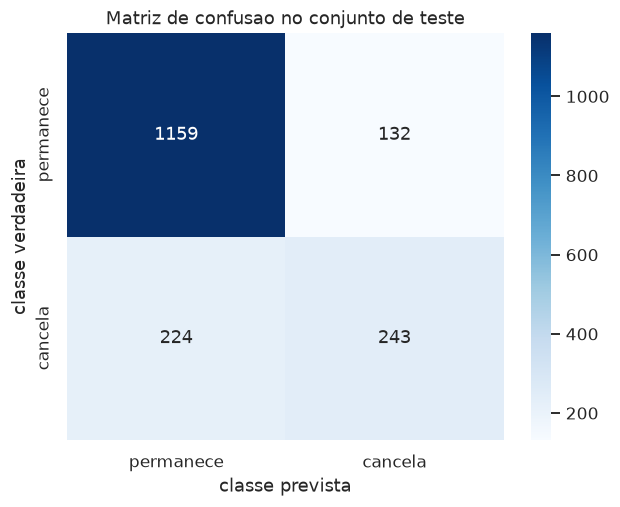

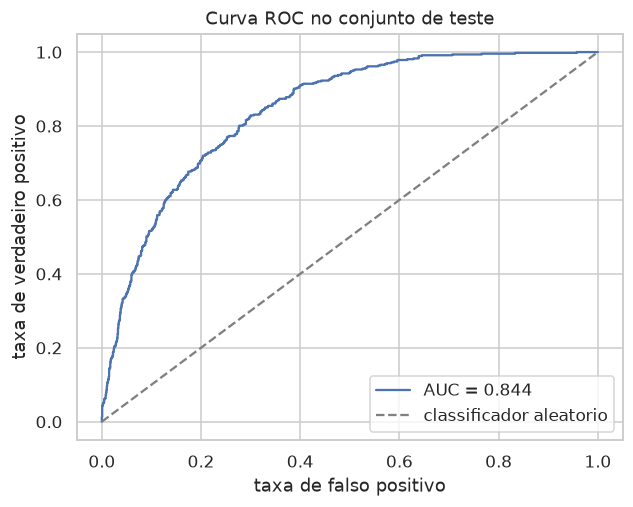

In [5]:
from mlalgos.metrics import confusion_matrix, curva_roc, f1_score, precision_score, recall_score, roc_auc_score

y_previsto = modelo.predict(X_teste_p)
y_escore = modelo.predict_proba(X_teste_p)[:, 1]
acuracia = float(np.mean(y_previsto == y_teste))
precisao = precision_score(y_teste, y_previsto, pos_label=1)
revocacao = recall_score(y_teste, y_previsto, pos_label=1)
f1 = f1_score(y_teste, y_previsto, pos_label=1)
auc = roc_auc_score(y_teste, y_escore, pos_label=1)
baseline = float(max(np.mean(y_teste == 1), np.mean(y_teste == 0)))
print(f"acuracia {acuracia:.3f} | baseline da classe majoritaria {baseline:.3f}")
print(f"precisao {precisao:.3f} | revocacao {revocacao:.3f} | f1 {f1:.3f} | roc_auc {auc:.3f}")
print("RESUMO_METRICAS " + json.dumps({
    "modelo": 'logistica_telco_ibm',
    "acuracia": acuracia,
    "precisao": precisao,
    "revocacao": revocacao,
    "f1": f1,
    "roc_auc": auc,
    "baseline_majoritaria": baseline,
}))

cm = confusion_matrix(y_teste, y_previsto, labels=[0, 1])
fig, ax = plt.subplots()
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=['permanece', 'cancela'], yticklabels=['permanece', 'cancela'], ax=ax,
)
ax.set_xlabel("classe prevista")
ax.set_ylabel("classe verdadeira")
ax.set_title("Matriz de confusao no conjunto de teste")
plt.show()

fpr, tpr, _ = curva_roc(y_teste, y_escore, pos_label=1)
fig, ax = plt.subplots()
ax.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="classificador aleatorio")
ax.set_xlabel("taxa de falso positivo")
ax.set_ylabel("taxa de verdadeiro positivo")
ax.set_title("Curva ROC no conjunto de teste")
ax.legend()
plt.show()


## 7) Desafios

1. Inclua `gender` e compare o F1. Se mudar pouco, por que ainda assim e melhor deixa-lo de fora deste exemplo?
2. `TotalCharges` e quase `tenure` vezes `MonthlyCharges`. Tire `TotalCharges` e veja se o AUC se mexe.
3. No teste, marque como positivo so quem tem probabilidade acima de 0,7. A precisao sobe? Quantos cancelamentos reais deixam de ser chamados?
